## Comprobar el entorno de  Qiskit <a id="install"></a>
En este Notebook se utilizar Qiskit para el diseño e implementación de circuitos cuánticos en simuladores y hardware real. Ya suponemos instalado Qiskit v2.0.
Lo primero, se comprueba la versión de Python del entorno y debe ser python>=3.10 para asegurar que sea compatible con la versión de Qiskit:

In [ ]:
from platform import python_version

print(python_version())

In [ ]:
import qiskit

print(f"Qiskit version: {qiskit.__version__}")


## Imports <a id="imports"></a>


In [3]:
from qiskit import QuantumRegister,ClassicalRegister, QuantumCircuit
from qiskit import transpile
from qiskit_aer import Aer
from qiskit_aer import AerSimulator

from qiskit.quantum_info import Statevector

from qiskit.visualization import plot_bloch_multivector, plot_histogram

# Importing standard Qiskit libraries
#from qiskit.visualization import *

import numpy as np
import matplotlib.pyplot as plt

## Creación de un circuito y simulacion desde un estado inicial

Se va a crear un circuito cuántico, se asigna el estado inicial y se evoluciona el estado con evolve

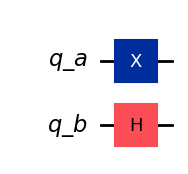

In [4]:

# Aquí creamos 2 registros cuánticos explícitamente antes de crear nuestro circuito
# Y obtenemos el vector de estado de la misma manera
# Luego representamos su multivector de Bloch

# Creamos dos registros cuánticos de 1 qubit cada uno
q_a = QuantumRegister(1, 'q_a')  # Registro cuántico llamado 'q_a'
q_b = QuantumRegister(1, 'q_b')  # Registro cuántico llamado 'q_b'

# Creamos un circuito cuántico que usa ambos registros
qc = QuantumCircuit(q_a, q_b)

# Aplicamos una puerta Hadamard al primer qubit (índice 0)
qc.x(0)

# Aplicamos una puerta X al mismo qubit
qc.h(1)

qc.draw('mpl')

In [5]:
#additionally, we are creating a Statevector object
#and priting out the state using LaTeX

#note that this statevector object DOES NOT require
#any kind of simulation to get the information


In [6]:
sv_ini = Statevector.from_label('11') # INICIALIZAR StateVector con .from_label(), tambien es posible con .from_int(), y más... ver docs!
sv_ini.draw('latex')

<IPython.core.display.Latex object>

In [7]:
sv_ini

Statevector([0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j],
            dims=(2, 2))


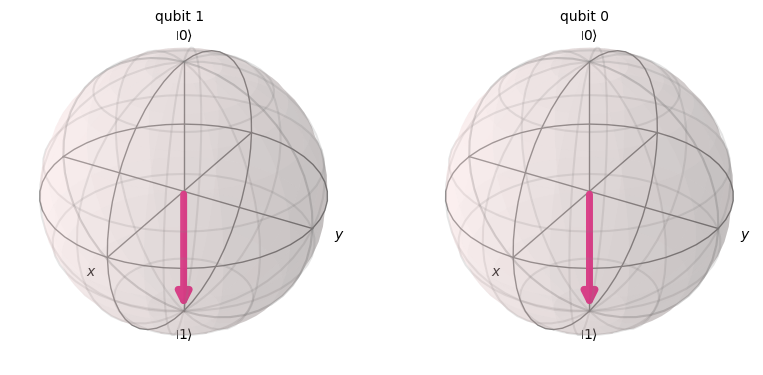

In [8]:
# Representamos el multivector de Bloch del estado cuántico de cada bit por separado
plot_bloch_multivector(sv_ini,reverse_bits=True)  # Estado inicial

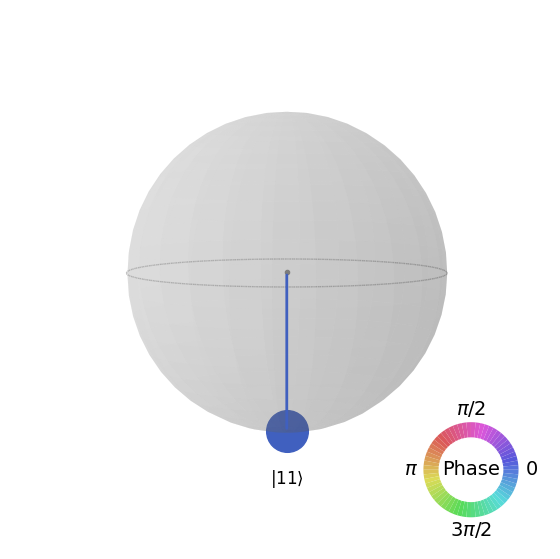

In [9]:
# Un Statevector puede representarse en qiskit como qsphere 
# método  .draw() cambiando  'latex' a 'qsphere'
sv_ini.draw('qsphere') 

In [11]:
# SIN SIMULADOR
sv_ev = sv_ini.evolve(qc) # evolucionar el estado inicial siguiedo el circuito
sv_ev.draw('latex') 

<IPython.core.display.Latex object>

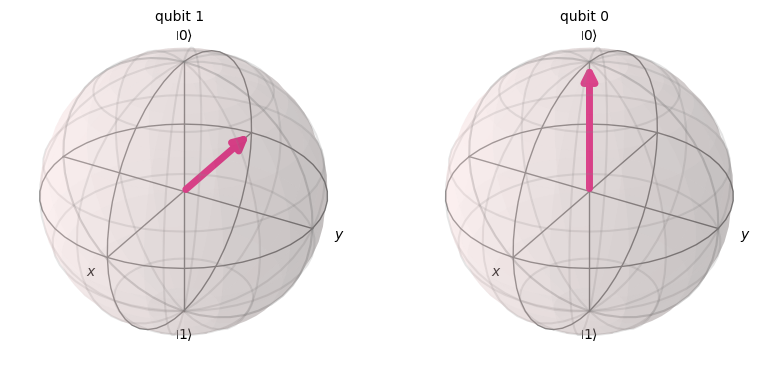

In [12]:
# Representamos el multivector de Bloch del estado cuántico de cada bit por separado
plot_bloch_multivector(sv_ev,reverse_bits=True)  # Estado evolucionado

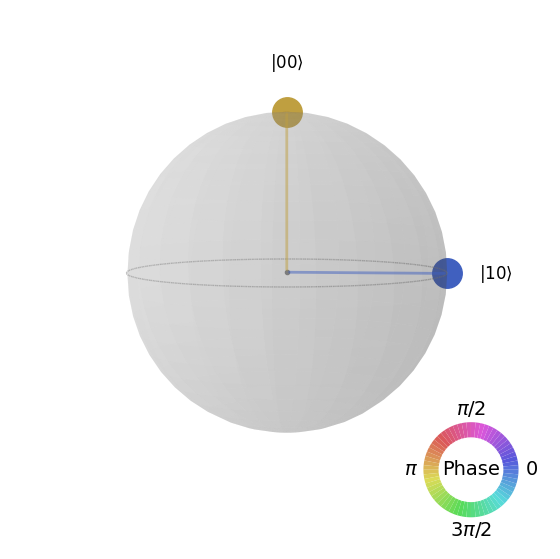

In [13]:
# Un Statevector puede representarse en qiskit como qsphere 
# método  .draw() cambiando  'latex' a 'qsphere'
sv_ev.draw('qsphere') 

In [14]:
# CON SIMULADOR, pero con cuidado de como se toma el estado inicial
# Repetimos el proceso pero utilizando un simulador
backend = Aer.get_backend('statevector_simulator')

In [15]:
# Ejecutamos el circuito en el simulador y comprobamos que NO sale el mismo resultado. ¿como se ha inicializado el estado de partida?
compiled_circuit = transpile(qc, backend)
result = backend.run(compiled_circuit).result()

# Obtenemos el vector de estado resultante
sv_sim= result.get_statevector()
sv_sim

Statevector([0.        +0.j, 0.70710678+0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [16]:
sv_sim.draw('latex') #we print out the state via. LaTeX

<IPython.core.display.Latex object>

In [17]:
sv_sim

Statevector([0.        +0.j, 0.70710678+0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


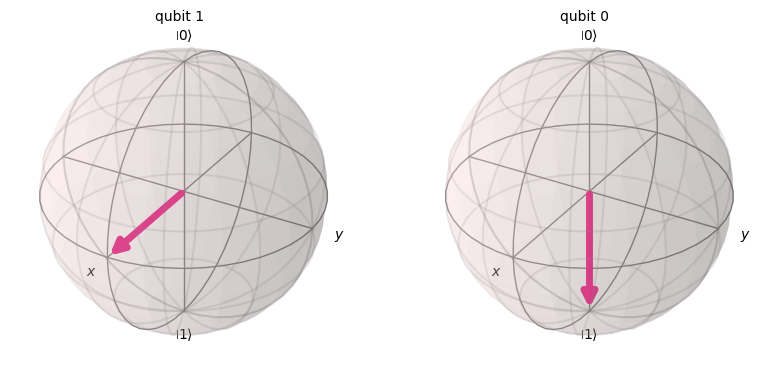

In [18]:
# Representamos el multivector de Bloch del estado cuántico
plot_bloch_multivector(sv_sim,reverse_bits=True)  # 

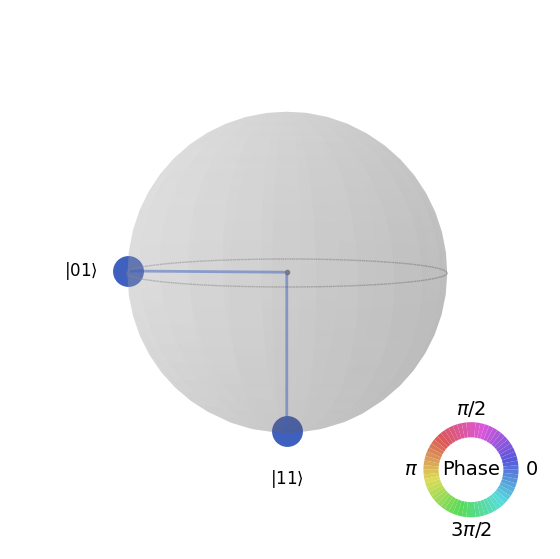

In [20]:
#the Statevector object can be directly drawn on a qsphere 
#with the same .draw() method by simply changing the call from 'latex' to 'qsphere'
#this will NOT be the case once we move on to the statevectors from simulation
sv_sim.draw('qsphere') 

## Inicializacion de un StateVector

In [21]:
sv1=Statevector([1/np.sqrt(2), 0, 0, -1/np.sqrt(2)])

In [22]:
sv1.draw('latex') 

<IPython.core.display.Latex object>

## Ejemplos de aplicacion de la esfera de Bloch


In [23]:
backend = Aer.get_backend('statevector_simulator')

# Estado de partida:

$$|ψ\rangle=\frac{|0\rangle+|1\rangle}{\sqrt{2}}$$

comprobar que este estado corresponde a ϕ = 0, θ=π/2.

Estado en la Esfera de Bloch 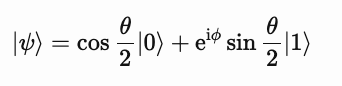

In [24]:
theta = np.pi/2
phi = 0

In [25]:
vector1qbit = np.array([np.cos(theta/2),np.exp(1j*phi)*np.sin(theta/2)])

In [26]:
vector1qbit

array([0.70710678+0.j, 0.70710678+0.j])

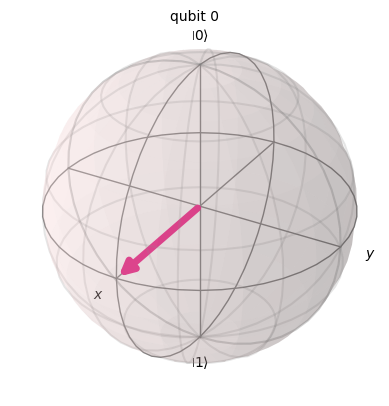

In [27]:
plot_bloch_multivector(vector1qbit)
# aunque permite su representación con vector hay que tener en cuenta que no es StateVector

In [29]:
# Inivcializamos un stateVector con los valores del vector
sv_estadoIni=Statevector(vector1qbit)

In [30]:
sv_estadoIni.draw('latex') 

<IPython.core.display.Latex object>

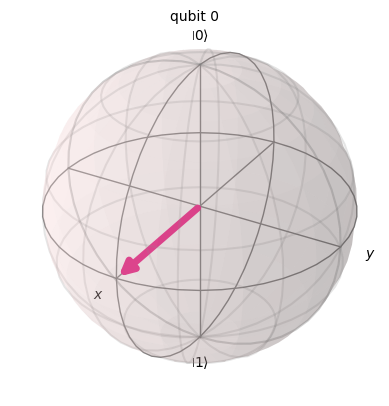

In [31]:
plot_bloch_multivector(sv_estadoIni)

Ejercicio:

Cambiar el estado sobre el eje X a un estado sobre el eje Y



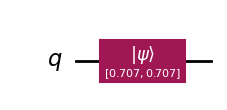

In [33]:
## Aplicar una rotacion de 90 grados sobre el eje Z es aplicar una puerta S

## Creamos un circuito de 1 qubit
qc1bitXtoY = QuantumCircuit(1)

## Adjuntamos una puerta Y
qc1bitXtoY.initialize(sv_estadoIni,0)

## Dibujamos el circuito
qc1bitXtoY.draw(output='mpl')

In [34]:
sv_estadoIni.draw('latex') 

<IPython.core.display.Latex object>

In [35]:
sv_estadoIni

Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


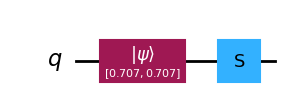

In [36]:
# Añadimos puerta S (rotación 90º sobre eje Z)
qc1bitXtoY.s(0)
qc1bitXtoY.draw(output='mpl')

In [37]:
# Ejecutamos el circuito en el simulador
compiled_circuit = transpile(qc1bitXtoY, backend)
result = backend.run(compiled_circuit).result()

# Obtenemos el vector de estado resultante
psi_finaly = result.get_statevector()
psi_finaly

Statevector([ 0.70710678+0.j        , -0.        +0.70710678j],
            dims=(2,))


In [38]:
psi_finaly.draw('latex') 

<IPython.core.display.Latex object>

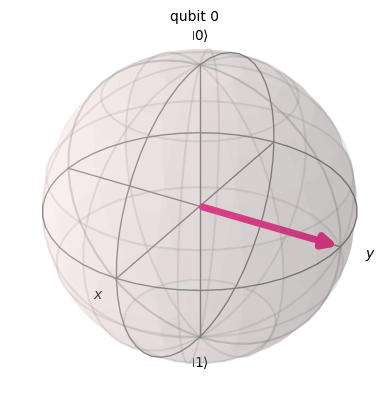

In [39]:
plot_bloch_multivector(psi_finaly)

In [41]:
vector=np.kron(psi_finaly,sv_estadoIni)
vector

array([ 0.5+0.j ,  0.5+0.j , -0. +0.5j, -0. +0.5j])

In [42]:
estado_final = Statevector(vector)
estado_final.draw('latex') 

<IPython.core.display.Latex object>

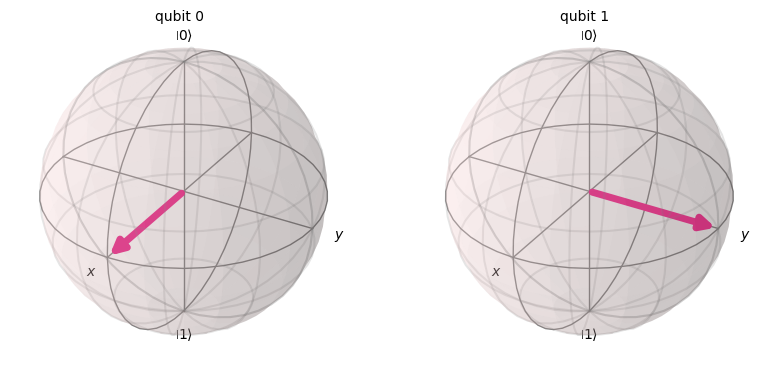

In [43]:
## Dibujamos los estados salida 
plot_bloch_multivector(estado_final)

# Estados de 2 qubits

In [46]:
## Creamos un estado de 2 qubits 
estado_2qubits = np.kron([0,1],[1,0])
estado_2qubits

array([0, 0, 1, 0])

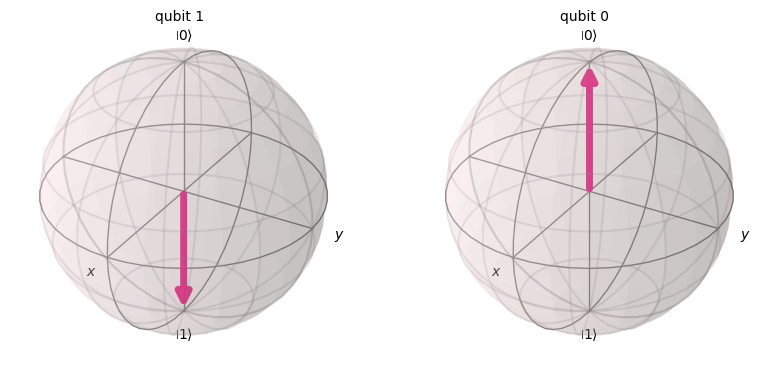

In [47]:
## Dibujamos los estados en la esfera de Bloch
plot_bloch_multivector(estado_2qubits, reverse_bits=True)


|+⟩=12(|0⟩+|1⟩)  y  |−⟩=12(|0⟩−|1⟩)

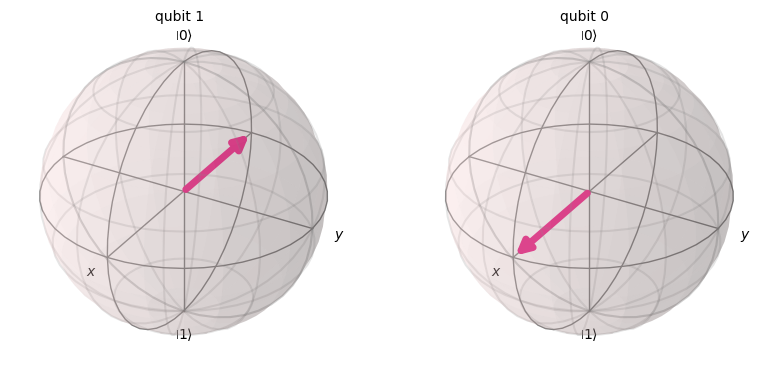

In [48]:
## Creamos un estado de 2 qubits y cargamos la base de signo
estadomas = np.kron([np.sqrt(1/2),-np.sqrt(1/2)],[np.sqrt(1/2),np.sqrt(1/2)])

## Dibujamos los estados en la esfera de Bloch
plot_bloch_multivector(estadomas,reverse_bits=True)

## Estados sobre el eje y

In [49]:
## Creamos una visualizacion del estado de 2 qubits OPCION1
EstadosEjeY = np.kron([np.sqrt(1/2),-1j*np.sqrt(1/2)],[np.sqrt(1/2),1j*np.sqrt(1/2)])

In [50]:
EstadosEjeY

array([0.5+0.j , 0. +0.5j, 0. -0.5j, 0.5+0.j ])

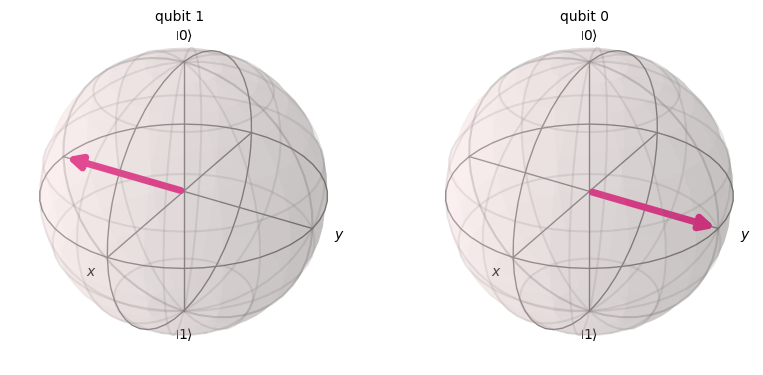

In [51]:
## Dibujamos los estados en la esfera de Bloch
plot_bloch_multivector(EstadosEjeY,reverse_bits=True)


In [52]:
## Creamos una visualizacion del estado de 2 qubits OPCION2
EstadosEjeY = np.kron([np.sqrt(1/2),-1j*np.sqrt(1/2)],[np.sqrt(1/2),1j*np.sqrt(1/2)])
sv_estadoy=Statevector(EstadosEjeY)
sv_estadoy.draw('latex') 

<IPython.core.display.Latex object>

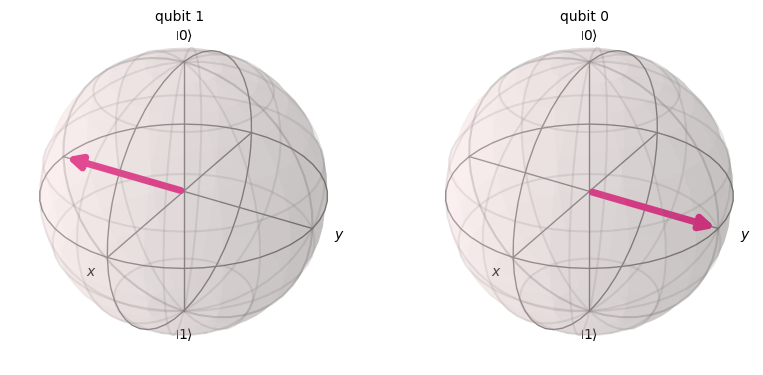

In [53]:
## Dibujamos los estados en la esfera de Bloch
plot_bloch_multivector(sv_estadoy,reverse_bits=True)

## Operador X

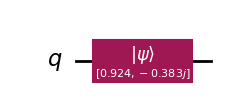

In [54]:
## Parametros vector de Bloch
theta = np.pi/4
phi = 3*np.pi/2
psi_inicial = np.array([np.cos(theta/2),np.exp(1j*phi)*np.sin(theta/2)])

## Creamos un circuito de 1 qubit
demoX = QuantumCircuit(1)

## Cargamos el estado inicial
demoX.initialize(psi_inicial,0)

## Dibujamos el circuito
demoX.draw(output='mpl')


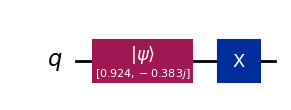

In [55]:
## Incluimos X de Pauli
demoX.x(0)

demoX.draw(output='mpl')

In [56]:
# Ejecutamos el circuito en el simulador
compiled_circuit = transpile(demoX, backend)
result = backend.run(compiled_circuit).result()

# Obtenemos el vector de estado resultante
psi_final = result.get_statevector()
psi_final

Statevector([-7.02978061e-17-0.38268343j,  9.23879533e-01+0.j        ],
            dims=(2,))


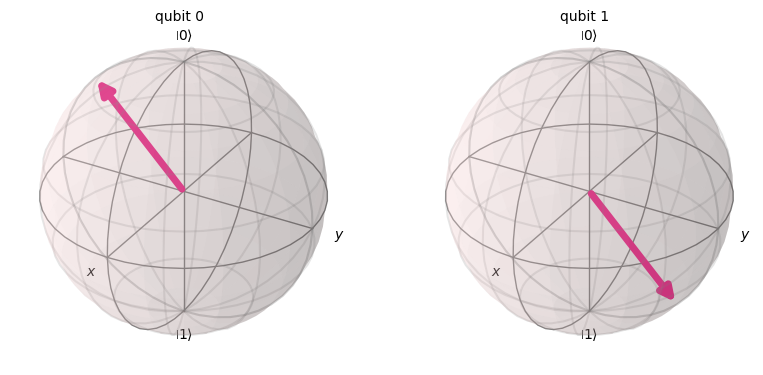

In [58]:
## Dibujamos los estados
plot_bloch_multivector(np.kron(psi_final,psi_inicial))

El qubit 0 representa el estado inicial, mientras que qubit 1, el final. 

## Operador Y

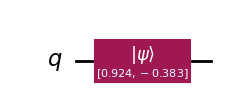

In [61]:
## Parametros vector de Bloch
theta = np.pi/4
phi = np.pi
psi_inicial = np.array([np.cos(theta/2),np.exp(1j*phi)*np.sin(theta/2)])

## Creamos un circuito de 1 qubit
qcdemoY = QuantumCircuit(1)

## Adjuntamos una puerta Y
qcdemoY.initialize(psi_inicial,0)

## Dibujamos el circuito
qcdemoY.draw(output='mpl')

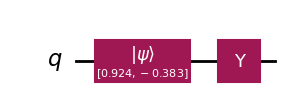

In [62]:
## Inlcuimos Y de Pauli
qcdemoY.y(0)

qcdemoY.draw(output='mpl')

In [63]:
# Ejecutamos el circuito en el simulador
compiled_circuit = transpile(qcdemoY, backend)
resultY = backend.run(compiled_circuit).result()

# Obtenemos el vector de estado resultante
psi_final = resultY.get_statevector()
psi_final


Statevector([4.68652041e-17+0.38268343j, 0.00000000e+00+0.92387953j],
            dims=(2,))


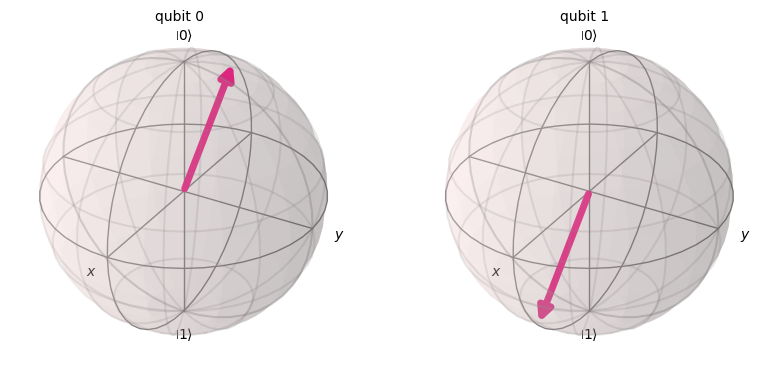

In [65]:

## Dibujamos los estados
plot_bloch_multivector(np.kron(psi_final,psi_inicial))

El qubit 0 representa el estado inicial, mientras que qubit 1, el final. 